In [1]:
import tensorflow as tf
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

In [2]:
RUTA_MODELO = "models/best.keras"

In [3]:
def plot_learning_curve(history):
    # Graficar precisión
    plt.figure()
    plt.plot(history.history['precision'], label='Training precision')
    plt.plot(history.history['val_precision'], label='Validation precision')
    plt.title('precision Curves')
    plt.legend()
    plt.show()

    # Graficar pérdida
    plt.figure()
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Loss Curves')
    plt.legend()
    plt.show()


In [4]:
datos = load_breast_cancer()

In [5]:
X = datos["data"]
y = datos["target"]

In [6]:
df = pd.DataFrame(X, columns=datos["feature_names"])

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

In [8]:
X_train, X_test_full, y_train, y_test_full = train_test_split(
    X, y, test_size=0.30, random_state=42
)

X_test, X_val, y_test, y_val= train_test_split(
    X_test_full, y_test_full, test_size=0.50, random_state=42
)


In [9]:
X_train.shape, X_test.shape, X_val.shape

((398, 30), (85, 30), (86, 30))

In [10]:
scaler = StandardScaler()
scaler.fit(X_train)

StandardScaler()

In [11]:
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)
X_val = scaler.transform(X_val)

In [12]:

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(units = 1, activation = "sigmoid")
])


model.compile(
    optimizer = "sgd",
    loss=tf.keras.losses.BinaryCrossentropy(from_logits=False),
    metrics=[tf.keras.metrics.Precision()] # Minimizar Falsos Positivos (0 significa Maligno | 1 Benigno)
)

In [13]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 1)              │            31 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31 (124.00 B)

 Trainable params: 31 (124.00 B)

 Non-trainable params: 0 (0.00 B)

In [14]:
model_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=RUTA_MODELO,
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    verbose=0,
)

In [15]:
history = model.fit(
    X_train,
    y_train,
    epochs = 200,
    validation_data = (X_val, y_val),
    callbacks = [model_checkpoint]
)

Epoch 1/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 72ms/step - loss: 0.5849 - precision: 0.8146 - val_loss: 0.5009 - val_precision: 0.8679
Epoch 2/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.4717 - precision: 0.8610 - val_loss: 0.4033 - val_precision: 0.8727
Epoch 3/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.3975 - precision: 0.8903 - val_loss: 0.3409 - val_precision: 0.9455
Epoch 4/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 0.3473 - precision: 0.9174 - val_loss: 0.2972 - val_precision: 0.9464
Epoch 5/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - loss: 0.3096 - precision: 0.9234 - val_loss: 0.2679 - val_precision: 1.0000
Epoch 6/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.2830 - precision: 0.9352 - val_loss: 0.2466 - val_precision: 1.0000
Epoch 7/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.2631 - precision: 0.9435 - val_loss: 0.2303 - val_precision: 1.0000
Epoch 8/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.2472 - precision: 0.9551 - v

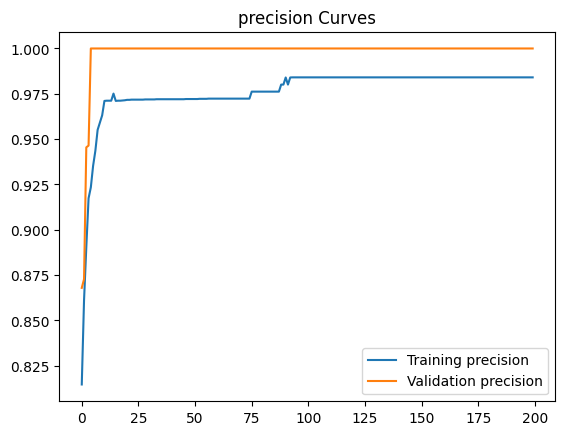

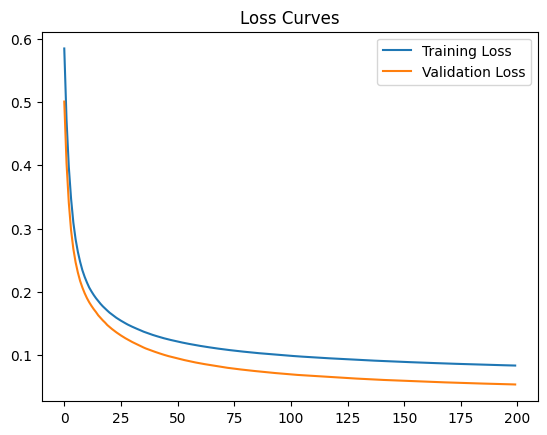

In [16]:
plot_learning_curve(history)

In [17]:
model = tf.keras.models.load_model(RUTA_MODELO)

In [18]:
y_predict = model.predict(X_test) > 0.5

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step


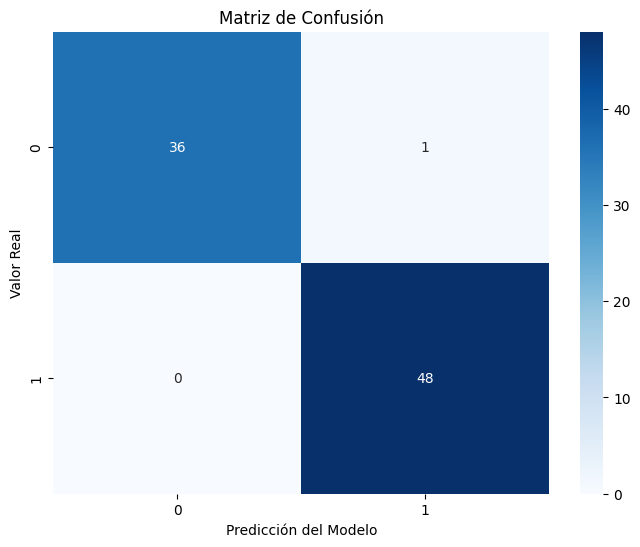

In [19]:
matriz_confusion = tf.math.confusion_matrix(labels=y_test, predictions=y_predict)
plt.figure(figsize=(8, 6))
sns.heatmap(matriz_confusion, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicción del Modelo')
plt.ylabel('Valor Real')
plt.title('Matriz de Confusión')
plt.show()